In [8]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import GofChisquarePower
from sklearn.cluster import KMeans
import sklearn.metrics as sil

In [9]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)
dim = pd.read_pickle('./data/phenotype/reduction_of_ae_2_dims_5001_seconds.pkl')
dim = pd.read_pickle('./data/phenotype/reduction_of_ae_2_dims_153_seconds.pkl')
humans = pd.concat([humans,dim.reindex(humans.index)], axis = 1)

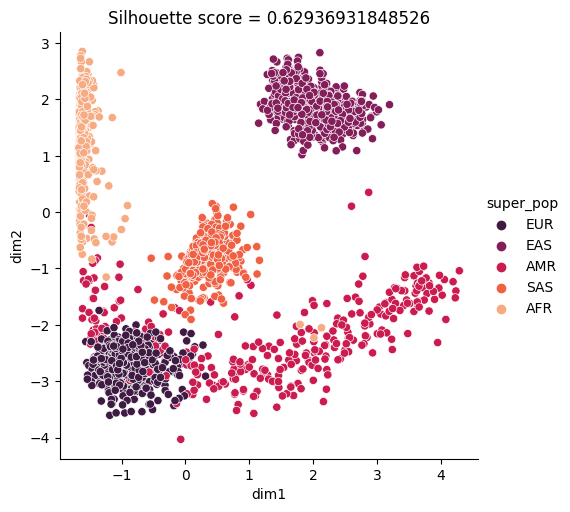

In [10]:
g = sns.relplot(
    data=humans,
    x="dim1", y="dim2",
    hue="super_pop",
    palette='rocket', sizes=(10, 200)).set(
    title=f"Silhouette score = {sil.silhouette_score(humans[['dim1','dim2']], humans['super_pop'], metric='euclidean')}")
plt.show()

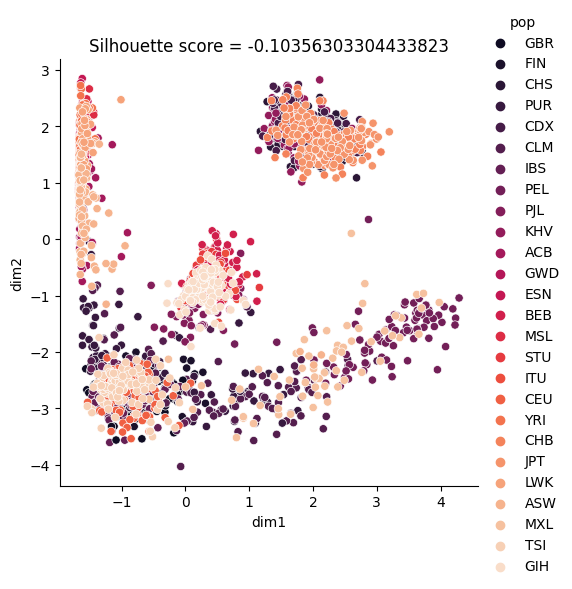

In [11]:
g = sns.relplot(
    data=humans,
    x="dim1", y="dim2",
    hue="pop",
    palette='rocket', sizes=(10, 200)).set(
    title=f"Silhouette score = {sil.silhouette_score(humans[['dim1','dim2']], humans['pop'], metric='euclidean')}")
plt.show()

### Silhouette score for super pop chrom 21

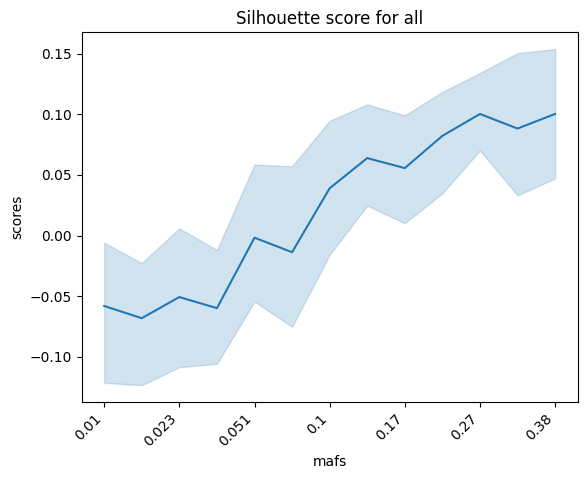

In [12]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir('./data/phenotype/reduced/21')]
dimsy = dims
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"./data/phenotype/reduced/21/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    humans[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    humans[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(humans[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], humans['super_pop'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores").set(
    title=f"Silhouette score for all")
plt.xticks(
    df['mafs'].iloc[::20], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

### Silhouette score for pop chrom 21

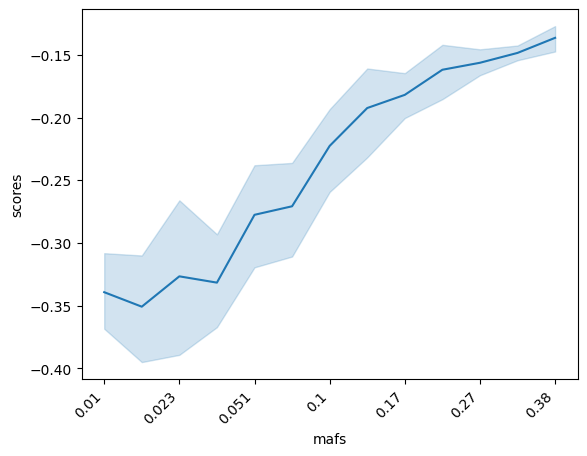

In [13]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir('./data/phenotype/reduced/21')]
dimsy = dims
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"./data/phenotype/reduced/21/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    humans[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    humans[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(humans[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], humans['pop'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::20], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

## sil for only africans

In [14]:
humans['ancestry'] = humans['super_pop']
humans['ancestry'].mask(humans['super_pop'] == 'AFR', 0, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'AMR', 1, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'EAS', 1, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'EUR', 1, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'SAS', 1, inplace=True)
humans

,sample,sample.1,pop,super_pop,gender,dim1,dim2,0_maf_0.051_dim1,0_maf_0.051_dim2,1_maf_0.01_dim1,...,125_maf_0.051_dim2,126_maf_0.01_dim1,126_maf_0.01_dim2,127_maf_0.13_dim1,127_maf_0.13_dim2,128_maf_0.17_dim1,128_maf_0.17_dim2,129_maf_0.051_dim1,129_maf_0.051_dim2,ancestry
0,HG00096,HG00096,GBR,EUR,male,-1.425541,-2.568410,0.631071,0.329427,-0.123524,...,-0.812080,-0.235343,-0.218960,-0.642920,-0.692276,0.114971,-0.622298,-0.794111,-0.182574,1
1,HG00097,HG00097,GBR,EUR,female,-1.440646,-2.603086,0.631071,0.329427,-0.123524,...,-0.812881,-0.247535,-0.226941,-1.067958,-0.905227,0.378843,-0.720485,-0.796376,-0.207104,1
2,HG00099,HG00099,GBR,EUR,female,-0.860363,-3.086992,0.631071,0.329427,-0.123524,...,-0.811117,-0.251744,-0.234500,-1.075417,-0.899947,0.167133,0.660257,-0.796320,-0.274055,1
3,HG00100,HG00100,GBR,EUR,female,-0.975774,-2.796563,0.611366,0.422687,-0.123524,...,-0.834916,-0.253003,-0.235801,-0.929539,-0.787464,0.135160,-0.613675,-0.793525,-0.572399,1
4,HG00101,HG00101,GBR,EUR,male,-0.637032,-3.063057,0.624443,0.323667,-0.123524,...,-0.794279,-0.251683,-0.234356,-1.143090,-1.088602,0.612544,0.509912,-0.806000,-0.190099,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,0.273707,-0.582326,0.625556,0.335603,-0.123524,...,-0.770680,-0.249232,-0.231100,-0.785998,-0.412796,-1.231501,-0.004286,-0.730811,0.128058,1
2500,NA21141,NA21141,GIH,SAS,female,0.299007,-0.676079,0.628692,0.321087,-0.123524,...,-0.766602,-0.239565,-0.218050,-0.716411,-0.370861,-1.231315,0.195799,-0.749836,-0.067839,1
2501,NA21142,NA21142,GIH,SAS,female,0.294150,-0.659157,0.609376,0.335941,-0.123524,...,-0.746249,-0.253003,-0.235801,0.160642,-0.662278,-1.193250,-0.179106,-0.509377,0.351229,1
2502,NA21143,NA21143,GIH,SAS,female,0.516370,-0.759748,0.626571,0.310303,-0.123524,...,-0.800125,-0.251591,-0.234264,-0.904258,-0.514284,-0.147032,-0.496191,-0.788679,-0.233490,1


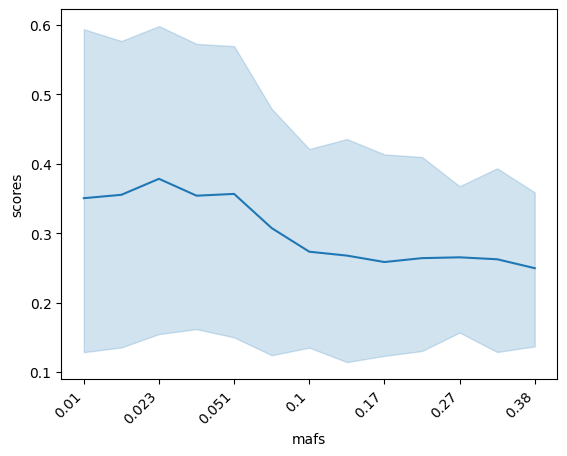

In [15]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir('./data/phenotype/reduced/21')]
dimsy = dims
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"./data/phenotype/reduced/21/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    humans[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    humans[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(humans[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], humans['ancestry'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::20], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

In [16]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)
humans['ancestry'] = humans['super_pop']
humans['ancestry'] = humans['super_pop']
humans['ancestry'].mask(humans['super_pop'] == 'AFR', 0, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'AMR', 1, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'EAS', 2, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'EUR', 3, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'SAS', 4, inplace=True)
afr = humans.loc[humans['ancestry'] == 0]
amr = humans.loc[humans['ancestry'] == 1]
eas = humans.loc[humans['ancestry'] == 2]
eur = humans.loc[humans['ancestry'] == 3]
sas = humans.loc[humans['ancestry'] == 4]
afr['subpops'] = afr['pop']
amr['subpops'] = 'other'
eas['subpops'] = 'other'
eur['subpops'] = 'other'
sas['subpops'] = 'other'

/tmp/ipykernel_652/1222539683.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  afr['subpops'] = afr['pop']
/tmp/ipykernel_652/1222539683.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  amr['subpops'] = 'other'
/tmp/ipykernel_652/1222539683.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html

In [17]:
afr_anal = pd.concat([afr, amr, eas, sas, eur]).sort_index()

In [18]:
afr_anal

,sample,sample.1,pop,super_pop,gender,ancestry,subpops
0,HG00096,HG00096,GBR,EUR,male,3,other
1,HG00097,HG00097,GBR,EUR,female,3,other
2,HG00099,HG00099,GBR,EUR,female,3,other
3,HG00100,HG00100,GBR,EUR,female,3,other
4,HG00101,HG00101,GBR,EUR,male,3,other
...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,4,other
2500,NA21141,NA21141,GIH,SAS,female,4,other
2501,NA21142,NA21142,GIH,SAS,female,4,other
2502,NA21143,NA21143,GIH,SAS,female,4,other


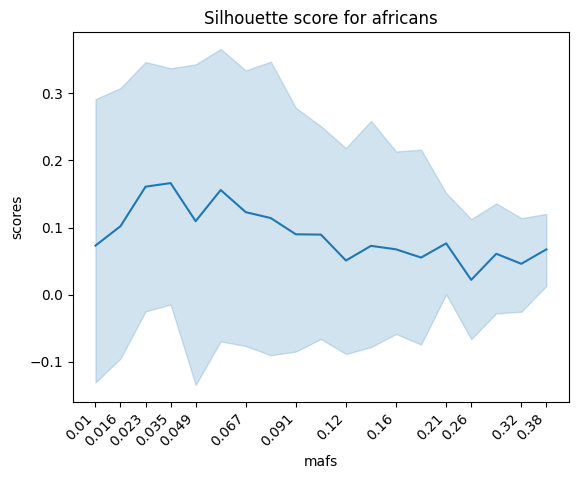

In [19]:
sil_scores = []
mafs = []

chroms = [21, 22]
for chrom in chroms:
    dimsy = [f for f in os.listdir(f"./data/phenotype/reduced/{chrom}")]
    for o in range(len(dimsy)):
        maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
        path_dim = f"./data/phenotype/reduced/{chrom}/{dimsy[o]}"
        mini_dim = pd.read_pickle(path_dim)
        afr_anal[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
        afr_anal[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
        score = sil.silhouette_score(afr_anal[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], afr_anal['subpops'], metric='euclidean')
        sil_scores.append(score)
        mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores").set(
    title=f"Silhouette score for africans")
plt.xticks(
    df['mafs'].iloc[::20], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

### Sil only for americans

In [20]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)
humans['ancestry'] = humans['super_pop']
humans['ancestry'] = humans['super_pop']
humans['ancestry'].mask(humans['super_pop'] == 'AFR', 0, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'AMR', 1, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'EAS', 2, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'EUR', 3, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'SAS', 4, inplace=True)
afr = humans.loc[humans['ancestry'] == 0]
amr = humans.loc[humans['ancestry'] == 1]
eas = humans.loc[humans['ancestry'] == 2]
eur = humans.loc[humans['ancestry'] == 3]
sas = humans.loc[humans['ancestry'] == 4]
afr['subpops'] = 'other'
amr['subpops'] = amr['pop']
eas['subpops'] = 'other'
eur['subpops'] = 'other'
sas['subpops'] = 'other'
amr_anal = pd.concat([afr, amr, eas, sas, eur]).sort_index()

/tmp/ipykernel_652/3395546184.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  afr['subpops'] = 'other'
/tmp/ipykernel_652/3395546184.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  amr['subpops'] = amr['pop']
/tmp/ipykernel_652/3395546184.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html

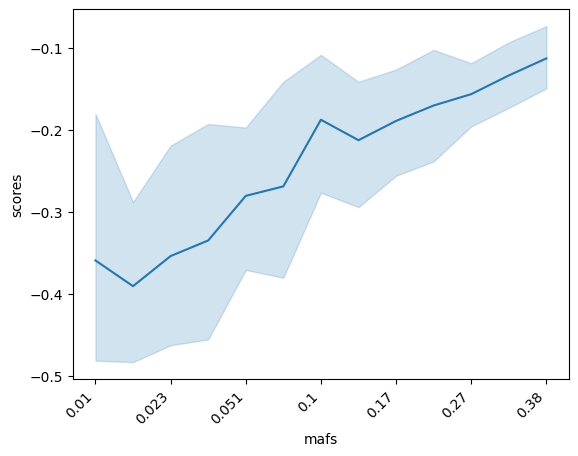

In [21]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir('./data/phenotype/reduced/21')]
dimsy = dims
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"./data/phenotype/reduced/21/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    amr_anal[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    amr_anal[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(amr_anal[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], amr_anal['subpops'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::20], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

## Sil only for europeans

In [22]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)
humans['ancestry'] = humans['super_pop']
humans['ancestry'] = humans['super_pop']
humans['ancestry'].mask(humans['super_pop'] == 'AFR', 0, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'AMR', 1, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'EAS', 2, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'EUR', 3, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'SAS', 4, inplace=True)
afr = humans.loc[humans['ancestry'] == 0]
amr = humans.loc[humans['ancestry'] == 1]
eas = humans.loc[humans['ancestry'] == 2]
eur = humans.loc[humans['ancestry'] == 3]
sas = humans.loc[humans['ancestry'] == 4]
afr['subpops'] = 'other'
amr['subpops'] = 'other'
eas['subpops'] = 'other'
eur['subpops'] = eur['pop']
sas['subpops'] = 'other'
eur_anal = pd.concat([afr, amr, eas, sas, eur]).sort_index()

/tmp/ipykernel_652/1468566709.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  afr['subpops'] = 'other'
/tmp/ipykernel_652/1468566709.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  amr['subpops'] = 'other'
/tmp/ipykernel_652/1468566709.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#re

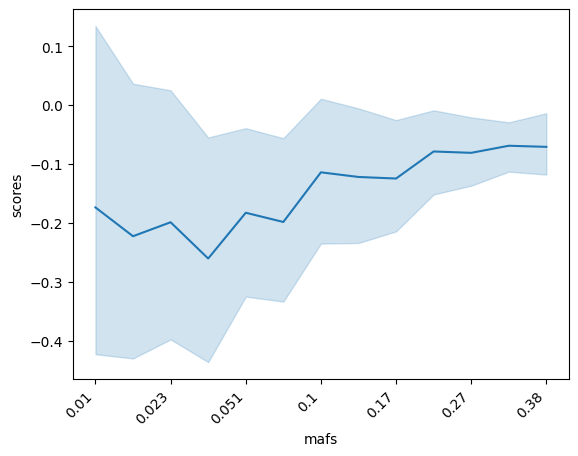

In [23]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir('./data/phenotype/reduced/21')]
dimsy = dims
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"./data/phenotype/reduced/21/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    eur_anal[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    eur_anal[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(eur_anal[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], eur_anal['subpops'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::20], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

## Sil for south east asians

In [24]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)
humans['ancestry'] = humans['super_pop']
humans['ancestry'] = humans['super_pop']
humans['ancestry'].mask(humans['super_pop'] == 'AFR', 0, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'AMR', 1, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'EAS', 2, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'EUR', 3, inplace=True)
humans['ancestry'].mask(humans['super_pop'] == 'SAS', 4, inplace=True)
afr = humans.loc[humans['ancestry'] == 0]
amr = humans.loc[humans['ancestry'] == 1]
eas = humans.loc[humans['ancestry'] == 2]
eur = humans.loc[humans['ancestry'] == 3]
sas = humans.loc[humans['ancestry'] == 4]
afr['subpops'] = 'other'
amr['subpops'] = 'other'
eas['subpops'] = 'other'
eur['subpops'] = 'other'
sas['subpops'] = sas['pop']
sas_anal = pd.concat([afr, amr, eas, sas, eur]).sort_index()

/tmp/ipykernel_652/2545181123.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  afr['subpops'] = 'other'
/tmp/ipykernel_652/2545181123.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  amr['subpops'] = 'other'
/tmp/ipykernel_652/2545181123.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#re

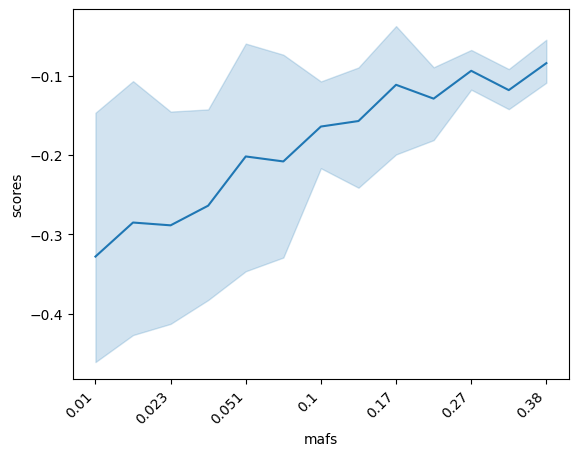

In [25]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir('./data/phenotype/reduced/21')]
dimsy = dims
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"./data/phenotype/reduced/21/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    sas_anal[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    sas_anal[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(sas_anal[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], sas_anal['subpops'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::20], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

# PCA

In [26]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)

In [27]:
# load snps

In [28]:
chrom =21

In [30]:
os.listdir(f"./data/genotype/chrom_{chrom}")

['4_4_800_4_maf_0.051_0.073.pkl',
 '0_8_800_0_maf_0.01_0.016.pkl',
 '12_8_800_12_maf_0.38_0.44.pkl',
 '3_7_800_3_maf_0.035_0.051.pkl',
 '4_7_800_4_maf_0.051_0.073.pkl',
 '9_5_1200_9_maf_0.21_0.27.pkl',
 '12_7_800_12_maf_0.38_0.44.pkl',
 '1_8_830_1_maf_0.016_0.023.pkl',
 '6_2_1200_6_maf_0.1_0.13.pkl',
 '4_9_1200_4_maf_0.051_0.073.pkl',
 '11_0_1200_11_maf_0.32_0.38.pkl',
 '10_2_1200_10_maf_0.27_0.32.pkl',
 '4_2_800_4_maf_0.051_0.073.pkl',
 '8_5_800_8_maf_0.17_0.21.pkl',
 '7_0_1200_7_maf_0.13_0.17.pkl',
 '2_7_800_2_maf_0.023_0.035.pkl',
 '10_1_1116_10_maf_0.27_0.32.pkl',
 '10_0_986_10_maf_0.27_0.32.pkl',
 '8_7_800_8_maf_0.17_0.21.pkl',
 '1_0_1200_1_maf_0.016_0.023.pkl',
 '1_2_800_1_maf_0.016_0.023.pkl',
 '8_0_980_8_maf_0.17_0.21.pkl',
 '4_5_1200_4_maf_0.051_0.073.pkl',
 '2_9_800_2_maf_0.023_0.035.pkl',
 '9_0_1200_9_maf_0.21_0.27.pkl',
 '12_3_800_12_maf_0.38_0.44.pkl',
 '2_5_800_2_maf_0.023_0.035.pkl',
 '0_0_1200_0_maf_0.01_0.016.pkl',
 '2_3_800_2_maf_0.023_0.035.pkl',
 '7_5_800_7_maf_0.13

In [31]:
snps = [f for f in os.listdir(f"./data/genotype/chrom_{chrom}") if f.split("_maf_")[1].split('.pkl')[0] == '0.17_0.21']
for snp in snps:
    maf = snp.split("_maf_")[1].split('.pkl')[0]
    path_snp = f"./data/genotype/chrom_{chrom}/{snp}"
    print(path_snp)

./data/genotype/chrom_21/8_5_800_8_maf_0.17_0.21.pkl
./data/genotype/chrom_21/8_7_800_8_maf_0.17_0.21.pkl
./data/genotype/chrom_21/8_0_980_8_maf_0.17_0.21.pkl
./data/genotype/chrom_21/8_1_1200_8_maf_0.17_0.21.pkl
./data/genotype/chrom_21/8_8_1200_8_maf_0.17_0.21.pkl
./data/genotype/chrom_21/8_6_800_8_maf_0.17_0.21.pkl
./data/genotype/chrom_21/8_9_1020_8_maf_0.17_0.21.pkl
./data/genotype/chrom_21/8_3_1200_8_maf_0.17_0.21.pkl
./data/genotype/chrom_21/8_4_800_8_maf_0.17_0.21.pkl
./data/genotype/chrom_21/8_2_1200_8_maf_0.17_0.21.pkl


In [32]:
geno = pd.read_pickle(path_snp)

In [34]:
from sklearn.decomposition import PCA
import pandas as pd

# Load data into a pandas DataFrame
data = geno

# Perform PCA with two principal components
pca = PCA(n_components=2)
principal_components = pca.fit_transform(data)

# Create a new DataFrame with the principal components
pca_df = pd.DataFrame(data = principal_components, columns = ['PC1', 'PC2'])

# Concatenate the original DataFrame with the principal components DataFrame
result_df = pd.concat([data, pca_df], axis = 1)

In [37]:
pca_df

,PC1,PC2
0,-2.318713,-2.348080
1,-4.059071,-0.412013
2,6.950185,1.019028
3,-2.893706,-1.454295
4,4.350716,3.611542
...,...,...
2499,-0.041195,-3.379640
2500,0.611990,-2.655016
2501,0.164525,-5.341291
2502,-1.363798,-2.857536


In [40]:
pca_df['PC1']

0      -2.318713
1      -4.059071
2       6.950185
3      -2.893706
4       4.350716
          ...   
2499   -0.041195
2500    0.611990
2501    0.164525
2502   -1.363798
2503    0.394911
Name: PC1, Length: 2504, dtype: float64

In [41]:
humans['PC1'] = pca_df['PC1']
humans['PC2'] = pca_df['PC2']

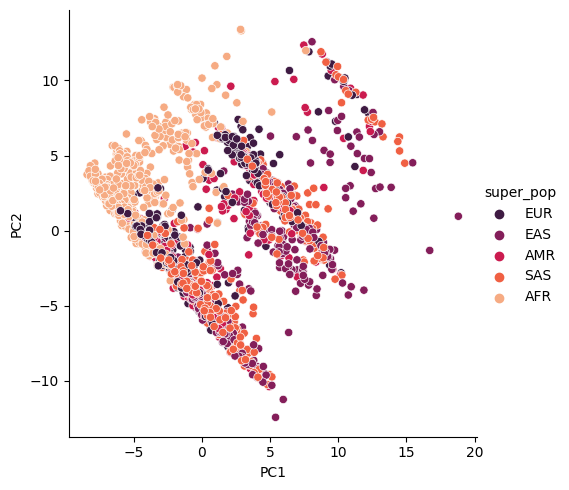

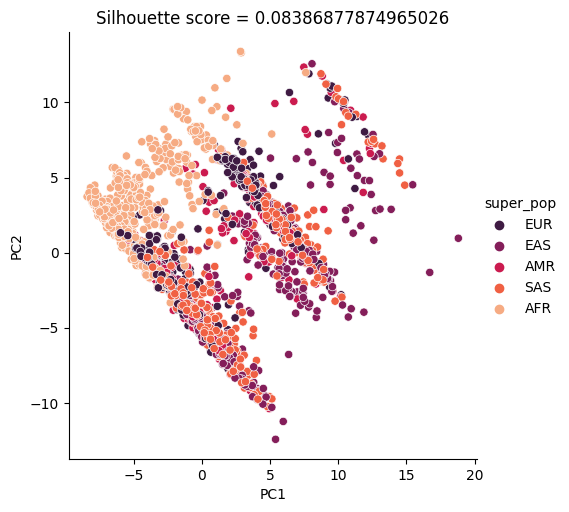

In [43]:
g = sns.relplot(
    data=humans,
    x="PC1", y="PC2",
    hue="super_pop",
    palette='rocket', sizes=(10, 200)).set(
    title=f"Silhouette score = {sil.silhouette_score(humans[['PC1','PC2']], humans['super_pop'], metric='euclidean')}")
plt.show()